# Program 13: the four metrics

**What:** turn the accuracy matrix into numbers you can put in a table.

**How:** write functions for: **RA**, average final accuracy on retained tasks; **FA**, average final accuracy on forgotten tasks (closer to chance is better); **Spill**, for each unlearn step, the sum of absolute accuracy changes on all other tasks; **Relapse**, for each forgotten task, |accuracy right after unlearning − accuracy at the end|. Put them in `common/metrics.py` and test them on a tiny hand-made matrix.

**Why:** these are UnCLe's metrics. Using the same definitions lets you compare directly with their results.

**Understanding note:** no single number is enough. A method can score a great FA simply by wrecking the whole model, which RA and Spill would expose.

**Done when:** your functions give the expected values on the hand-made matrix, then report all four for program 12.

## Where this fits (for a first-time reader)

Program 12 saved a table: the accuracy of every class after every request of a stream. Plots of it are good for *seeing* spill and relapse, but a paper needs **numbers**, so that methods can be compared in one table. This program defines those numbers, tests them, and computes them for program 12's runs. Every later method (programs 17–20) is scored with exactly these functions.

| Metric | Question it answers | Good value |
|---|---|---|
| **RA** (retain accuracy) | do the tasks we kept still work at the end? | high |
| **FA** (forget accuracy) | are the forgotten tasks really gone at the end? | near chance (10% task-IL, 1% class-IL) |
| **Spill** | when we forget one task, how much do the *other* tasks change at that moment? | low |
| **Relapse** | after forgetting, does the forgotten task's accuracy move back up later? | low |

The code is in `common/metrics.py`.

## 1. Setup

In [1]:
import gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics
for module in (common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.features, common.metrics):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.metrics import all_metrics, item_view
from common.utils import RESULTS_DIR, log_run

SETTINGS = {
    "runs": ["task15_seed0", "handmade_worst", "handmade_best"],   # program 12 result files to score
}

## 2. The definitions, with a hand-made example

Take 3 tasks and the stream `L0 → L1 → U0 → L2`. Suppose the accuracies (task-IL) after each request were:

| after request | task 0 | task 1 | task 2 |
|---|---|---|---|
| `L0` | 0.80 | – | – |
| `L1` | 0.70 | 0.90 | – |
| `U0` | **0.10** | 0.80 | – |
| `L2` | **0.30** | 0.75 | 0.85 |

Worked by hand:
- **RA** = mean final accuracy of the kept tasks 1 and 2 = (0.75 + 0.85) / 2 = **0.80**
- **FA** = final accuracy of the forgotten task 0 = **0.30**
- **Spill** of `U0` = change in the other kept task (task 1) at that request = |0.80 − 0.90| = **0.10**. (Task 2 isn't learned yet, so it doesn't count.)
- **Relapse** of task 0 = |final − right after `U0`| = |0.30 − 0.10| = **0.20**. Task 0 came back from 10% to 30% while task 2 was learned.

The cell checks that the functions give exactly these numbers.

In [2]:
n = np.nan
acc = np.array([[0.80, n,    n   ],
                [0.70, 0.90, n   ],
                [0.10, 0.80, n   ],
                [0.30, 0.75, 0.85]])
learned = ~np.isnan(acc)
forgotten = np.array([[0, 0, 0], [0, 0, 0], [1, 0, 0], [1, 0, 0]], dtype=bool)
unlearn_rows = [(2, 0)]   # request row 2 unlearned task 0

m = all_metrics(acc, learned, forgotten, unlearn_rows)
expected = {"RA": 0.80, "FA": 0.30, "Spill": 0.10, "Relapse": 0.20}
for k, v in expected.items():
    ok = abs(m[k] - v) < 1e-9
    print(f"{k:>8}: got {m[k]:.4f}, expected {v:.2f}  {'OK' if ok else 'WRONG'}")
    assert ok, k
print("\nall four metrics match the hand-made values")

      RA: got 0.8000, expected 0.80  OK
      FA: got 0.3000, expected 0.30  OK
   Spill: got 0.1000, expected 0.10  OK
 Relapse: got 0.2000, expected 0.20  OK

all four metrics match the hand-made values


## 3. Two edge cases

1. **Spill only counts tasks that are learned and still kept**, both before and after the `U`. A task learned later can't spill, and the forgotten task itself is not "spill".
2. **Relapse is an absolute value.** A forgotten task that keeps *falling* after its `U` (it wasn't fully forgotten yet, and other learning pushes it further down) also counts. UnCLe defines it this way: any movement after forgetting means the state was not stable. In the tables below we also print the signed *rise*, so you can see which direction it moved.

A second hand-made case checks both: 4 tasks, stream `L0 → L1 → U1 → L2 → U0 → L3`.

In [3]:
acc2 = np.array([[0.80, n,    n,    n   ],
                 [0.70, 0.90, n,    n   ],
                 [0.65, 0.20, n,    n   ],
                 [0.60, 0.15, 0.85, n   ],
                 [0.12, 0.10, 0.80, n   ],
                 [0.10, 0.25, 0.75, 0.90]])
learned2 = ~np.isnan(acc2)
forgotten2 = np.zeros_like(learned2)
forgotten2[2:, 1] = True
forgotten2[4:, 0] = True
m2 = all_metrics(acc2, learned2, forgotten2, [(2, 1), (4, 0)])
# By hand:
#   U1 at row 2: other kept tasks learned before = task 0: |0.65-0.70| = 0.05
#   U0 at row 4: other kept tasks = task 2 (task 1 is already forgotten): |0.80-0.85| = 0.05 -> Spill = 0.05
#   Relapse task 1: |0.25-0.20| = 0.05 ; task 0: |0.10-0.12| = 0.02 -> mean 0.035
#   RA = mean(0.75, 0.90) = 0.825 ; FA = mean(0.10, 0.25) = 0.175
expected2 = {"RA": 0.825, "FA": 0.175, "Spill": 0.05, "Relapse": 0.035}
for k, v in expected2.items():
    ok = abs(m2[k] - v) < 1e-9
    print(f"{k:>8}: got {m2[k]:.4f}, expected {v:.3f}  {'OK' if ok else 'WRONG'}")
    assert ok, k

      RA: got 0.8250, expected 0.825  OK
      FA: got 0.1750, expected 0.175  OK
   Spill: got 0.0500, expected 0.050  OK
 Relapse: got 0.0350, expected 0.035  OK


## 4. The four metrics for program 12

`item_view` turns program 12's per-class table into a per-task table (or keeps classes at class level), and `all_metrics` scores it. We report task-IL (chance 10%) and class-IL (chance 1%).

Runs that were not done are skipped.

In [4]:
scores = {}
for run in SETTINGS["runs"]:
    path = RESULTS_DIR / f"12_{run}.npz"
    if not path.exists():
        print(f"{run}: {path.name} not found (run program 12 with this stream), skipped")
        continue
    d = np.load(path)
    for kind in ("til", "cil"):
        acc, learned, forgotten, unlearn_rows = item_view(d, kind)
        scores[(run, kind)] = all_metrics(acc, learned, forgotten, unlearn_rows)

print(f"{'run':>16} {'acc':>4} | {'RA':>6} {'FA':>6} {'Spill':>6} {'Relapse':>8}")
for (run, kind), m in scores.items():
    print(f"{run:>16} {kind:>4} | {m['RA']*100:5.1f}% {m['FA']*100:5.1f}% {m['Spill']*100:6.1f} {m['Relapse']*100:8.1f}")
print("\nSpill and Relapse are in percentage points.")

             run  acc |     RA     FA  Spill  Relapse
    task15_seed0  til |  79.6%  27.9%    6.0     18.1
    task15_seed0  cil |  50.8%   0.2%   17.9     18.2
  handmade_worst  til |  77.3%  19.6%    0.0      9.6
  handmade_worst  cil |  42.3%   0.0%    0.0     10.0
   handmade_best  til |  74.4%  30.7%   30.8      0.0
   handmade_best  cil |  41.6%   0.3%   34.9      0.0

Spill and Relapse are in percentage points.


## 5. Behind the averages

Spill and Relapse are averages over the `U` requests. The table below shows each `U` of the main run separately: its spill, and the forgotten task's accuracy right after it and at the end. Program 11's "later L's" (tasks learned after it) is listed too: the prediction was that more later learning means more relapse.

task15_seed0, task-IL:
 request later Ls   spill | before U  after U    end   rise  relapse
      U5        6     4.3 |     72.8     45.4   23.6  -21.8     21.8
      U3        4     2.4 |     71.4     46.9   22.2  -24.7     24.7
      U2        4     5.9 |     81.7     45.9   28.6  -17.3     17.3
      U8        3     9.0 |     86.2     79.0   52.3  -26.7     26.7
      U4        0     8.4 |     78.7     13.0   13.0   +0.0      0.0

task15_seed0, class-IL:
 request later Ls   spill | before U  after U    end   rise  relapse
      U5        6    11.8 |     50.5     12.4    0.0  -12.4     12.4
      U3        4    15.3 |     41.4      6.8    0.5   -6.3      6.3
      U2        4     6.7 |     59.2     14.2    0.0  -14.2     14.2
      U8        3    38.3 |     83.2     57.9    0.0  -57.9     57.9
      U4        0    17.3 |     32.2      0.3    0.3   +0.0      0.0



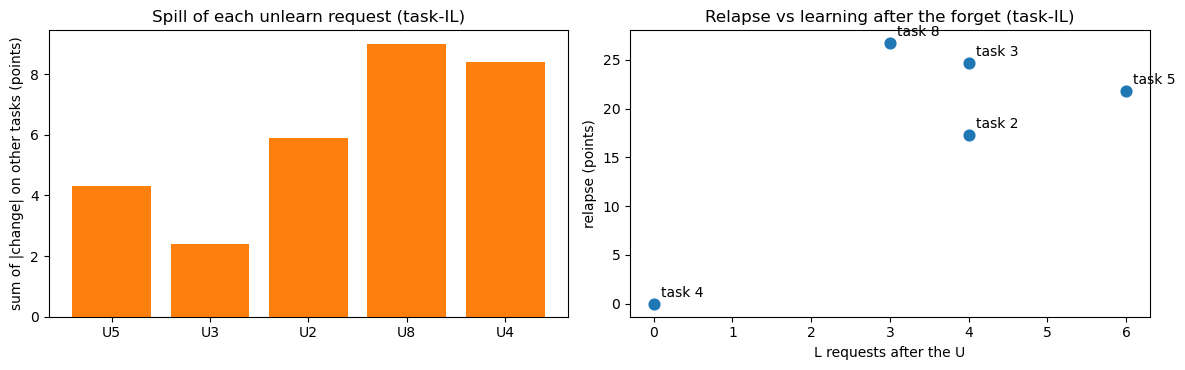

In [5]:
from common.stream import learning_after_forget, load_stream

main = SETTINGS["runs"][0]
if (main, "til") in scores:
    d = np.load(RESULTS_DIR / f"12_{main}.npz")
    stream = load_stream(RESULTS_DIR / "streams" / f"{main}.json")["requests"]
    later = {pos: k for pos, _, k in learning_after_forget(stream)}
    for kind in ("til", "cil"):
        acc, learned, forgotten, unlearn_rows = item_view(d, kind)
        m = scores[(main, kind)]
        print(f"{main}, {'task-IL' if kind == 'til' else 'class-IL'}:")
        print(f"{'request':>8} {'later Ls':>8} {'spill':>7} | {'before U':>8} {'after U':>8} {'end':>6} {'rise':>6} {'relapse':>8}")
        for (r, item), sp, rel in zip(unlearn_rows, m["spill_list"], m["relapse_list"]):
            before, after, end = acc[r - 1, item], acc[r, item], acc[-1, item]
            print(f"{'U' + str(item):>8} {later[r]:8d} {sp*100:7.1f} | {before*100:8.1f} {after*100:8.1f} {end*100:6.1f} "
                  f"{(end - after)*100:+6.1f} {rel*100:8.1f}")
        print()

    acc, learned, forgotten, unlearn_rows = item_view(d, "til")
    m = scores[(main, "til")]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    labels = [f"U{i}" for _, i in unlearn_rows]
    axes[0].bar(labels, np.array(m["spill_list"]) * 100, color="tab:orange")
    axes[0].set(title="Spill of each unlearn request (task-IL)", ylabel="sum of |change| on other tasks (points)")
    axes[1].scatter([later[r] for r, _ in unlearn_rows], np.array(m["relapse_list"]) * 100, s=60)
    for (r, i), y in zip(unlearn_rows, m["relapse_list"]):
        axes[1].annotate(f"task {i}", (later[r], y * 100), textcoords="offset points", xytext=(5, 5))
    axes[1].set(title="Relapse vs learning after the forget (task-IL)", xlabel="L requests after the U",
                ylabel="relapse (points)")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "13_spill_relapse.png", dpi=120)
    plt.show()

## 6. Why one number isn't enough

The understanding note says a method can get a perfect FA by wrecking the model. Here's a fake "method" that does exactly that: it sets every task, kept or forgotten, to chance (10%) at the first `U`. Its FA is perfect, and RA and Spill expose it.

In [6]:
if (main, "til") in scores:
    acc, learned, forgotten, unlearn_rows = item_view(np.load(RESULTS_DIR / f"12_{main}.npz"), "til")
    wrecked = acc.copy()
    first_u = unlearn_rows[0][0]
    wrecked[first_u:] = np.where(learned[first_u:], 0.10, np.nan)
    mw = all_metrics(wrecked, learned, forgotten, unlearn_rows)
    for name, m in [("program 12 (DER++ + BadTeacher)", scores[(main, "til")]), ("'wreck everything'", mw)]:
        print(f"{name:>32}: RA {m['RA']*100:5.1f}%  FA {m['FA']*100:5.1f}%  Spill {m['Spill']*100:5.1f}  Relapse {m['Relapse']*100:5.1f}")

 program 12 (DER++ + BadTeacher): RA  79.6%  FA  27.9%  Spill   6.0  Relapse  18.1
              'wreck everything': RA  10.0%  FA  10.0%  Spill  40.3  Relapse   0.0


## 7. Log the run

In [7]:
log_run("13_metrics", SETTINGS,
        {f"{run}_{kind}": {k: (round(v, 4) if isinstance(v, float) else [round(x, 4) for x in v]) for k, v in m.items()}
         for (run, kind), m in scores.items()})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Program 12's four numbers (task-IL): which one looks worst?
2. Does relapse grow with the number of tasks learned after the forget (section 5)?
3. Worst vs best stream: same task forgotten, different order. How different are their Relapse and FA?
4. Why does the "wreck everything" method get a perfect FA, and which metrics catch it?
5. Relapse is an absolute value. Did any forgotten task move *down* after its `U` instead of up? What does that mean?